# Extreme Value Analysis 

## 0. Setup and data loading

In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.stats import genextreme, genpareto, poisson, chi2
from scipy.special import gammaln
from scipy.optimize import minimize

import statsmodels.api as sm
import statsmodels.formula.api as smf

In [3]:
CSV_PATH = "paris_weather_data.csv"
OUT_DIR = "figures_evt_summer"
os.makedirs(OUT_DIR, exist_ok=True)

df = pd.read_csv(CSV_PATH)

df["time"] = pd.to_datetime(df["time"])
df = df.sort_values("time").reset_index(drop=True)

cols = [c for c in ["time", "tmax", "tavg", "prcp"] if c in df.columns]
df = df[cols].copy()

df["year"] = df["time"].dt.year
df["month"] = df["time"].dt.month

print(df.head())
print("Years covered:", df["year"].min(), "-", df["year"].max(), "| n_years =", df["year"].nunique())
print("Columns:", df.columns.tolist())


        time  tmax  prcp  year  month
0 1990-01-01   0.8   0.2  1990      1
1 1990-01-02   2.4   0.2  1990      1
2 1990-01-03   1.8   0.0  1990      1
3 1990-01-04   4.5   0.0  1990      1
4 1990-01-05   5.2   0.0  1990      1
Years covered: 1990 - 2025 | n_years = 36
Columns: ['time', 'tmax', 'prcp', 'year', 'month']


## 1. Evidence: month of annual maxima

Month counts of annual maxima:
 month
6     6
7    15
8    14
9     1
Name: count, dtype: int64
Share of annual maxima occurring in JJA (Jun-Jul-Aug): 0.972


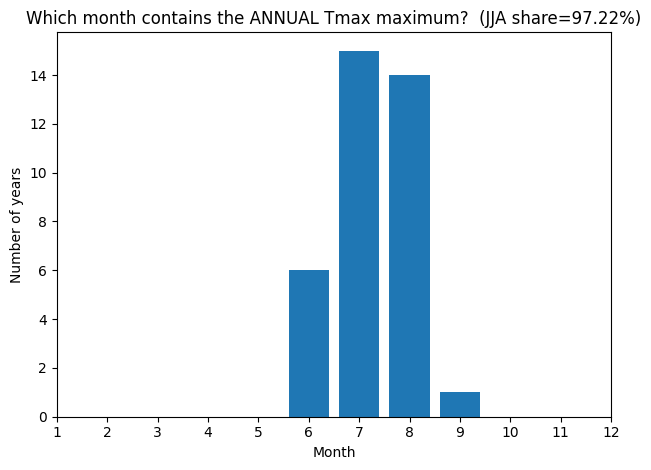

In [4]:
assert "tmax" in df.columns, "Need tmax for heat extremes"

tmp = df[["time", "year", "month", "tmax"]].dropna().copy()

idx = tmp.groupby("year")["tmax"].idxmax()
annual_max_days = tmp.loc[idx].sort_values("year")

month_counts = annual_max_days["month"].value_counts().sort_index()
share_JJA = month_counts.loc[month_counts.index.isin([6, 7, 8])].sum() / month_counts.sum()

print("Month counts of annual maxima:\n", month_counts)
print(f"Share of annual maxima occurring in JJA (Jun-Jul-Aug): {share_JJA:.3f}")

plt.figure()
plt.bar(month_counts.index.astype(int), month_counts.values)
plt.xticks(range(1, 13))
plt.title(f"Which month contains the ANNUAL Tmax maximum?  (JJA share={share_JJA:.2%})")
plt.xlabel("Month")
plt.ylabel("Number of years")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "annual_max_month.png"), dpi=200)
plt.show()
plt.close()

## 2. Evidence: all-year vs JJA distribution

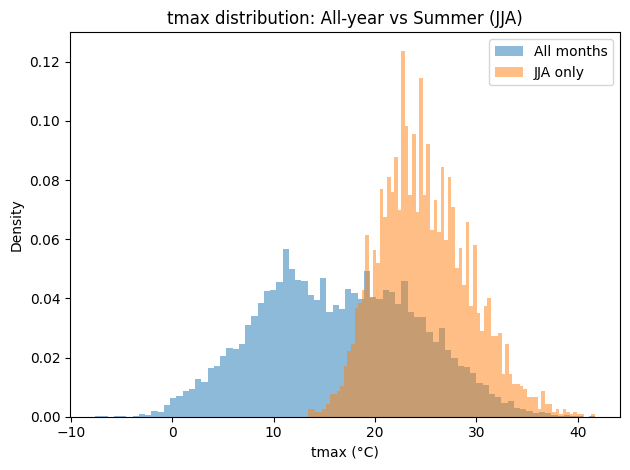

All-year tmax quantiles: [16.3 26.7 29.1 33.3]
JJA-only tmax quantiles: [24.5   30.9   32.745 36.489]


In [5]:
df_summer = df[df["month"].isin([6, 7, 8])].copy()

x_all = df["tmax"].dropna().astype(float).values
x_jja = df_summer["tmax"].dropna().astype(float).values

plt.figure()
plt.hist(x_all, bins=80, alpha=0.5, density=True, label="All months")
plt.hist(x_jja, bins=80, alpha=0.5, density=True, label="JJA only")
plt.title("tmax distribution: All-year vs Summer (JJA)")
plt.xlabel("tmax (°C)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "temperature_distribution.png"), dpi=200)
plt.show()
plt.close()

print("All-year tmax quantiles:", np.quantile(x_all, [0.5, 0.9, 0.95, 0.99]))
print("JJA-only tmax quantiles:", np.quantile(x_jja, [0.5, 0.9, 0.95, 0.99]))

## 3. Evidence: monthly seasonality of daily maximum temperature

/var/folders/lz/syrxszk52cj9wlkn0_27ftmm0000gn/T/ipykernel_14540/1946185025.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=list(range(1, 13)), showfliers=False)


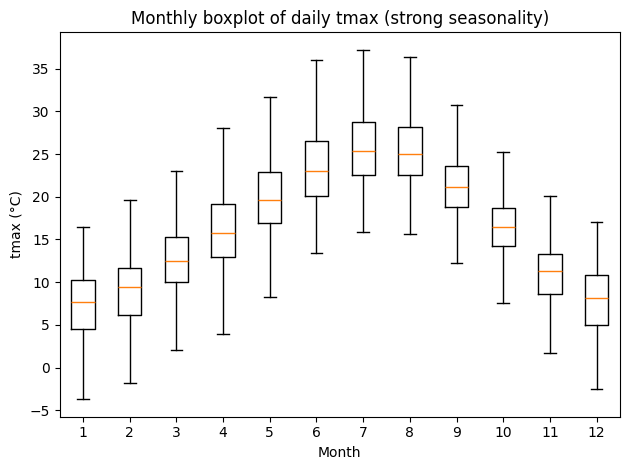

In [6]:
data = [tmp[tmp["month"] == m]["tmax"].values for m in range(1, 13)]

plt.figure()
plt.boxplot(data, labels=list(range(1, 13)), showfliers=False)
plt.title("Monthly boxplot of daily tmax (strong seasonality)")
plt.xlabel("Month")
plt.ylabel("tmax (°C)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "monthly_boxplot_tmax.png"), dpi=200)
plt.show()
plt.close()

## 4. JJA block maxima construction

   year  tmax_jja_max
0  1990          37.4
1  1991          34.7
2  1992          36.0
3  1993          31.3
4  1994          36.2
Number of years with JJA maxima: 36


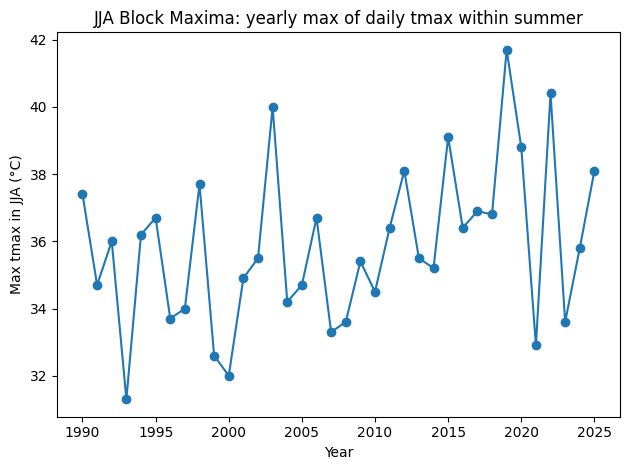

In [7]:
jja = df_summer[["year", "tmax"]].dropna().copy()

bm_jja = jja.groupby("year")["tmax"].max().reset_index(name="tmax_jja_max")
print(bm_jja.head())
print("Number of years with JJA maxima:", len(bm_jja))

plt.figure()
plt.plot(bm_jja["year"], bm_jja["tmax_jja_max"], marker="o")
plt.title("JJA Block Maxima: yearly max of daily tmax within summer")
plt.xlabel("Year")
plt.ylabel("Max tmax in JJA (°C)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "jja_block_maxima_timeseries.png"), dpi=200)
plt.show()
plt.close()

## 5. GEV fit on JJA block maxima

GEV params: xi = -0.16714414578663866 loc = 34.909241682816116 scale = 2.1664900845168704
SciPy parameterization check: c = 0.16714414578663866 = -xi
LR test GEV vs Gumbel (xi=0): LR = 1.594, p-value = 0.2068
Bootstrap successful fits: 1000 / 1000


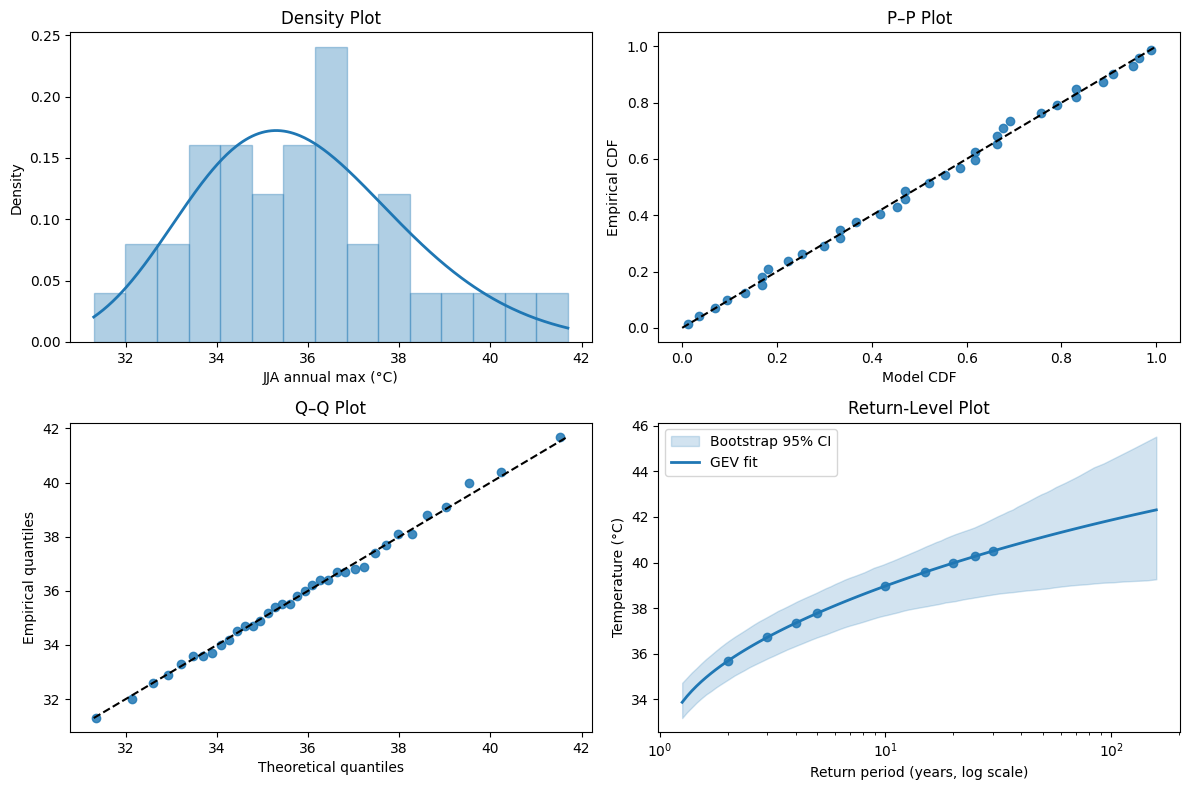

In [8]:
# Fit GEV on JJA block maxima + diagnostics
bm = np.asarray(bm_jja["tmax_jja_max"].values.astype(float))
bm = bm[~np.isnan(bm)]

c_gev, loc, scale = genextreme.fit(bm)
xi_gev = -c_gev  

c_gumbel, loc_gumbel, scale_gumbel = genextreme.fit(bm, f0=0.0)
ll_gev = np.sum(genextreme.logpdf(bm, c_gev, loc=loc, scale=scale))
ll_gumbel = np.sum(genextreme.logpdf(bm, c_gumbel, loc=loc_gumbel, scale=scale_gumbel))
lr_gev = 2.0 * (ll_gev - ll_gumbel)
pval_lr_gev = 1.0 - chi2.cdf(lr_gev, df=1)

print("GEV params: xi =", xi_gev, "loc =", loc, "scale =", scale)
print("SciPy parameterization check: c =", c_gev, "= -xi")
print(f"LR test GEV vs Gumbel (xi=0): LR = {lr_gev:.3f}, p-value = {pval_lr_gev:.4f}")

bm_sorted = np.sort(bm)
n = len(bm_sorted)

p_emp = (np.arange(1, n + 1) - 0.5) / n

# return levels at selected T
Ts = np.array([2, 3, 4, 5, 10, 15, 20, 25, 30], dtype=float)
ps = 1.0 - 1.0 / Ts
zT = genextreme.ppf(ps, c_gev, loc=loc, scale=scale)


# Bootstrap CI for return levels
n_boot = 1000
rng = np.random.default_rng(42)

t_model = np.logspace(0.1, 2.2, 100)
p_model_line = 1.0 - 1.0 / t_model
z_model_line = genextreme.ppf(p_model_line, c_gev, loc=loc, scale=scale)

boot_rl = np.full((n_boot, len(t_model)), np.nan)

for b in range(n_boot):

    bm_boot = rng.choice(bm, size=n, replace=True)

    try:
        c_b, loc_b, scale_b = genextreme.fit(bm_boot)

        if scale_b <= 0:
            continue

        boot_rl[b, :] = genextreme.ppf(
            p_model_line, c_b, loc=loc_b, scale=scale_b
        )

    except Exception:
        continue

boot_rl = boot_rl[~np.isnan(boot_rl).all(axis=1)]

rl_lower = np.nanpercentile(boot_rl, 2.5, axis=0)
rl_upper = np.nanpercentile(boot_rl, 97.5, axis=0)

print(f"Bootstrap successful fits: {boot_rl.shape[0]} / {n_boot}")


fig, axes = plt.subplots(2, 2, figsize=(12, 8))

main_color = "C0"
ref_color = "black"
ci_alpha = 0.20


# Density plot
xs = np.linspace(bm_sorted.min(), bm_sorted.max(), 300)
pdf = genextreme.pdf(xs, c_gev, loc=loc, scale=scale)

axes[0, 0].hist(
    bm_sorted,
    bins=15,
    density=True,
    alpha=0.35,
    color=main_color,
    edgecolor=main_color
)

axes[0, 0].plot(xs, pdf, linewidth=2.0, color=main_color)

axes[0, 0].set_title("Density Plot")
axes[0, 0].set_xlabel("JJA annual max (°C)")
axes[0, 0].set_ylabel("Density")

# P-P plot
p_model = genextreme.cdf(bm_sorted, c_gev, loc=loc, scale=scale)

axes[0, 1].plot(
    p_model,
    p_emp,
    "o",
    color=main_color,
    alpha=0.85
)

axes[0, 1].plot(
    [0, 1],
    [0, 1],
    linewidth=1.5,
    color=ref_color,
    linestyle="--"
)

axes[0, 1].set_title("P–P Plot")
axes[0, 1].set_xlabel("Model CDF")
axes[0, 1].set_ylabel("Empirical CDF")

# Q–Q plot
q_theo = genextreme.ppf(p_emp, c_gev, loc=loc, scale=scale)
q_emp = bm_sorted

mn = min(q_theo.min(), q_emp.min())
mx = max(q_theo.max(), q_emp.max())

axes[1, 0].plot(
    q_theo,
    q_emp,
    "o",
    color=main_color,
    alpha=0.85
)

axes[1, 0].plot(
    [mn, mx],
    [mn, mx],
    linewidth=1.5,
    color=ref_color,
    linestyle="--"
)

axes[1, 0].set_title("Q–Q Plot")
axes[1, 0].set_xlabel("Theoretical quantiles")
axes[1, 0].set_ylabel("Empirical quantiles")

# Return-level plot
axes[1, 1].fill_between(
    t_model,
    rl_lower,
    rl_upper,
    color=main_color,
    alpha=ci_alpha,
    label="Bootstrap 95% CI"
)

axes[1, 1].plot(
    t_model,
    z_model_line,
    linewidth=2.0,
    color=main_color,
    label="GEV fit"
)

axes[1, 1].plot(
    Ts,
    zT,
    "o",
    color=main_color,
    alpha=0.85
)

axes[1, 1].set_xscale("log")
axes[1, 1].set_title("Return-Level Plot")
axes[1, 1].set_xlabel("Return period (years, log scale)")
axes[1, 1].set_ylabel("Temperature (°C)")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "gev_diagnostics_jja.png"), dpi=200)
plt.show()
plt.close()


## 6. Declustering, POT helper functions and mean excess analysis

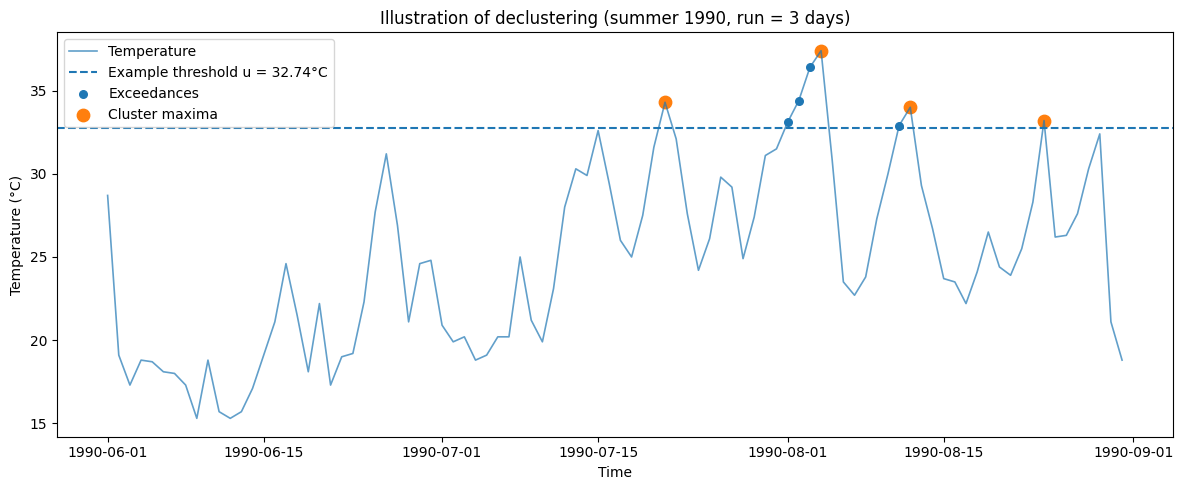

In [9]:
df_summer = df_summer.copy()
df_summer["time"] = pd.to_datetime(df_summer["time"])

x = df_summer["tmax"].dropna().astype(float).values
RUN_DECLUSTER = 3


def decluster_exceedances(df_in: pd.DataFrame, value_col: str, u: float, run: int = 3):
    d = (
        df_in[["time", value_col]]
        .dropna()
        .sort_values("time")
        .reset_index(drop=True)
        .copy()
    )
    d["value"] = d[value_col].astype(float)

    exc = d[d["value"] > u].copy()
    if exc.empty:
        return np.array([]), pd.DataFrame(
            columns=[
                "cluster",
                "cluster_start",
                "cluster_end",
                "cluster_max_excess",
                "cluster_peak_value",
                "peak_time",
                "n_days",
            ]
        )

    exc["excess"] = exc["value"] - u
    exc = exc.reset_index(drop=True)

    cluster_ids = [0]
    cid = 0
    for i in range(1, len(exc)):
        gap_days = (exc.loc[i, "time"] - exc.loc[i - 1, "time"]).days
        if gap_days >= run:
            cid += 1
        cluster_ids.append(cid)

    exc["cluster"] = cluster_ids

    # keep cluster maxima + the time of the peak
    idx_peak = exc.groupby("cluster")["value"].idxmax()
    peak_rows = exc.loc[idx_peak, ["cluster", "time"]].rename(columns={"time": "peak_time"})

    cluster_max = (
        exc.groupby("cluster", as_index=False)
        .agg(
            cluster_start=("time", "min"),
            cluster_end=("time", "max"),
            cluster_max_excess=("excess", "max"),
            cluster_peak_value=("value", "max"),
            n_days=("time", "size"),
        )
        .merge(peak_rows, on="cluster", how="left")
        .sort_values("cluster_start")
        .reset_index(drop=True)
    )

    return cluster_max["cluster_max_excess"].to_numpy(dtype=float), cluster_max


def mean_excess(df_in: pd.DataFrame, value_col: str, u: float, run: int = 3):
    exc, _ = decluster_exceedances(df_in, value_col=value_col, u=u, run=run)
    if len(exc) == 0:
        return np.nan
    return np.mean(exc)


# Declustering illustration plot
# example threshold for illustration only 
U_DEMO = float(np.quantile(x, 0.95))

exc_vals_demo, clusters_demo = decluster_exceedances(
    df_summer, value_col="tmax", u=U_DEMO, run=RUN_DECLUSTER
)

years = np.sort(df_summer["time"].dt.year.dropna().unique())
year_demo = int(years[0])  

df_plot = (
    df_summer[df_summer["time"].dt.year == year_demo]
    .sort_values("time")
    .copy()
)

exc_plot = df_plot[df_plot["tmax"] > U_DEMO].copy()

cluster_peaks_plot = clusters_demo[
    clusters_demo["peak_time"].dt.year == year_demo
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    df_plot["time"],
    df_plot["tmax"],
    linewidth=1.2,
    alpha=0.7,
    label="Temperature"
)

plt.axhline(
    U_DEMO,
    linestyle="--",
    linewidth=1.5,
    label=f"Example threshold u = {U_DEMO:.2f}°C"
)

plt.scatter(
    exc_plot["time"],
    exc_plot["tmax"],
    s=30,
    label="Exceedances"
)

if not cluster_peaks_plot.empty:
    plt.scatter(
        cluster_peaks_plot["peak_time"],
        cluster_peaks_plot["cluster_peak_value"],
        s=80,
        marker="o",
        label="Cluster maxima"
    )

plt.title(f"Illustration of declustering (summer {year_demo}, run = {RUN_DECLUSTER} days)")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()

plt.savefig(os.path.join(OUT_DIR, "Example_of_declustering.png"), dpi=200)
plt.show()
plt.close()

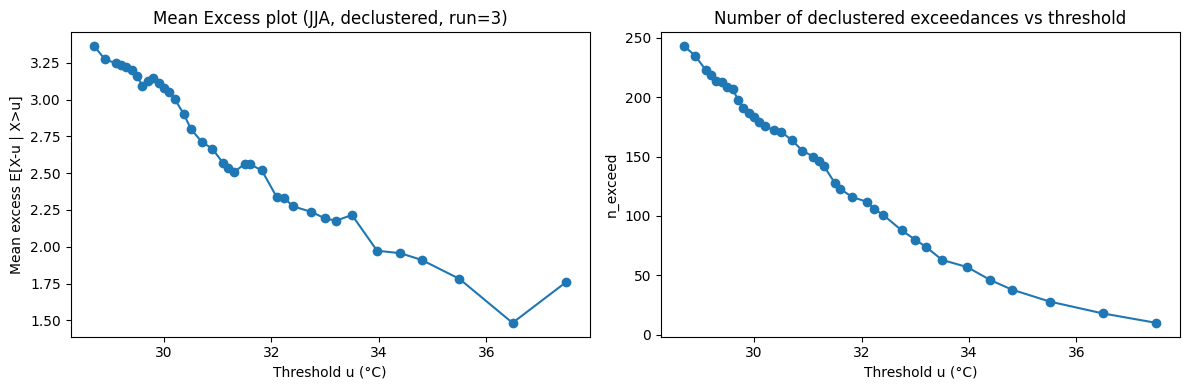

In [10]:
def fit_gpd_at_u(df_in: pd.DataFrame, value_col: str, u: float, min_exc: int = 20, run: int = 3):

    exc, clusters = decluster_exceedances(
        df_in,
        value_col=value_col,
        u=u,
        run=run
    )

    if len(exc) < min_exc:
        return None

    # fit GPD
    c, loc, beta = genpareto.fit(exc, floc=0)

    return {
        "u": float(u),
        "n_exc": int(len(exc)),
        "xi": float(c),
        "beta": float(beta),
    }

qs = np.linspace(0.80, 0.995, 40)
us = np.unique(np.quantile(x, qs))

me = np.array([
    mean_excess(df_summer, "tmax", float(u), run=RUN_DECLUSTER)
    for u in us
])

nexc = np.array([
    len(decluster_exceedances(df_summer, "tmax", float(u), run=RUN_DECLUSTER)[0])
    for u in us
])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Mean excess plot
axes[0].plot(us, me, marker="o")
axes[0].set_title(f"Mean Excess plot (JJA, declustered, run={RUN_DECLUSTER})")
axes[0].set_xlabel("Threshold u (°C)")
axes[0].set_ylabel("Mean excess E[X-u | X>u]")

# Number of declustered exceedances vs threshold
axes[1].plot(us, nexc, marker="o")
axes[1].set_title("Number of declustered exceedances vs threshold")
axes[1].set_xlabel("Threshold u (°C)")
axes[1].set_ylabel("n_exceed")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "threshold_diagnostics.png"), dpi=200)
plt.show()
plt.close()

## 7. POT stability plots under declustering

      u  n_exc        xi      beta
0  28.7    243 -0.291022  4.318150
1  28.9    235 -0.281585  4.179893
2  29.1    223 -0.285143  4.152538
3  29.2    219 -0.288182  4.141839
4  29.3    214 -0.289321  4.120487
         u  n_exc        xi      beta
30  33.500     63 -0.249363  2.765495
31  33.967     57 -0.176237  2.324920
32  34.400     46 -0.204128  2.359805
33  34.800     38 -0.214561  2.325971
34  35.500     28 -0.213900  2.170749


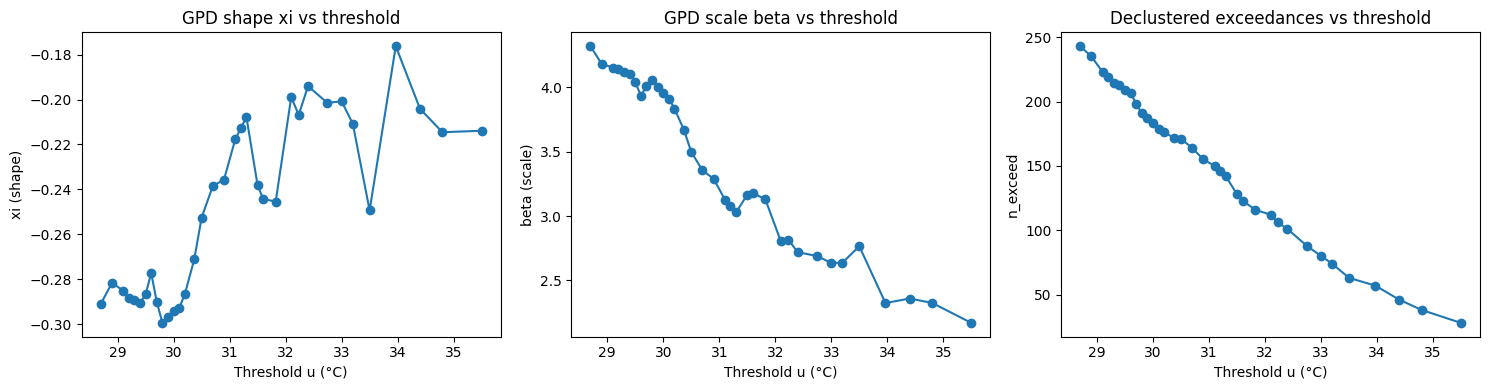

In [11]:
rows = []
for u in us:
    r = fit_gpd_at_u(df_summer, "tmax", float(u), min_exc=20, run=RUN_DECLUSTER)
    if r is not None:
        rows.append(r)

stab = pd.DataFrame(rows)
print(stab.head())
print(stab.tail())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# xi stability 
axes[0].plot(stab["u"], stab["xi"], marker="o")
axes[0].set_title("GPD shape xi vs threshold")
axes[0].set_xlabel("Threshold u (°C)")
axes[0].set_ylabel("xi (shape)")

# beta stability 
axes[1].plot(stab["u"], stab["beta"], marker="o")
axes[1].set_title("GPD scale beta vs threshold")
axes[1].set_xlabel("Threshold u (°C)")
axes[1].set_ylabel("beta (scale)")

# exceedance count 
axes[2].plot(stab["u"], stab["n_exc"], marker="o")
axes[2].set_title("Declustered exceedances vs threshold")
axes[2].set_xlabel("Threshold u (°C)")
axes[2].set_ylabel("n_exceed")

plt.tight_layout()

plt.savefig(os.path.join(OUT_DIR, "threshold_stability.png"), dpi=200)
plt.show()
plt.close()


## 8. Threshold selection for the declustered POT model

In [12]:
u_star = 34.8
print("Chosen threshold u* =", u_star)

Chosen threshold u* = 34.8


## 9. POT helper: return-level function

In [13]:
def pot_return_level(u, xi, beta, rate_per_year, T):
    lam = rate_per_year
    if abs(xi) < 1e-10:
        return u + beta * np.log(T * lam)
    return u + (beta / xi) * ((T * lam) ** xi - 1.0)

## 9. Final declustered POT-GPD fit and diagnostics

Fitted Params: xi = -0.2146, beta = 2.3260
Annual exceedance rate (lambda): 1.056
LR test GPD vs Exponential (xi=0): LR = 1.352, p-value = 0.2449
Starting Bootstrap...
Bootstrap complete. Successful fits: 1000/1000


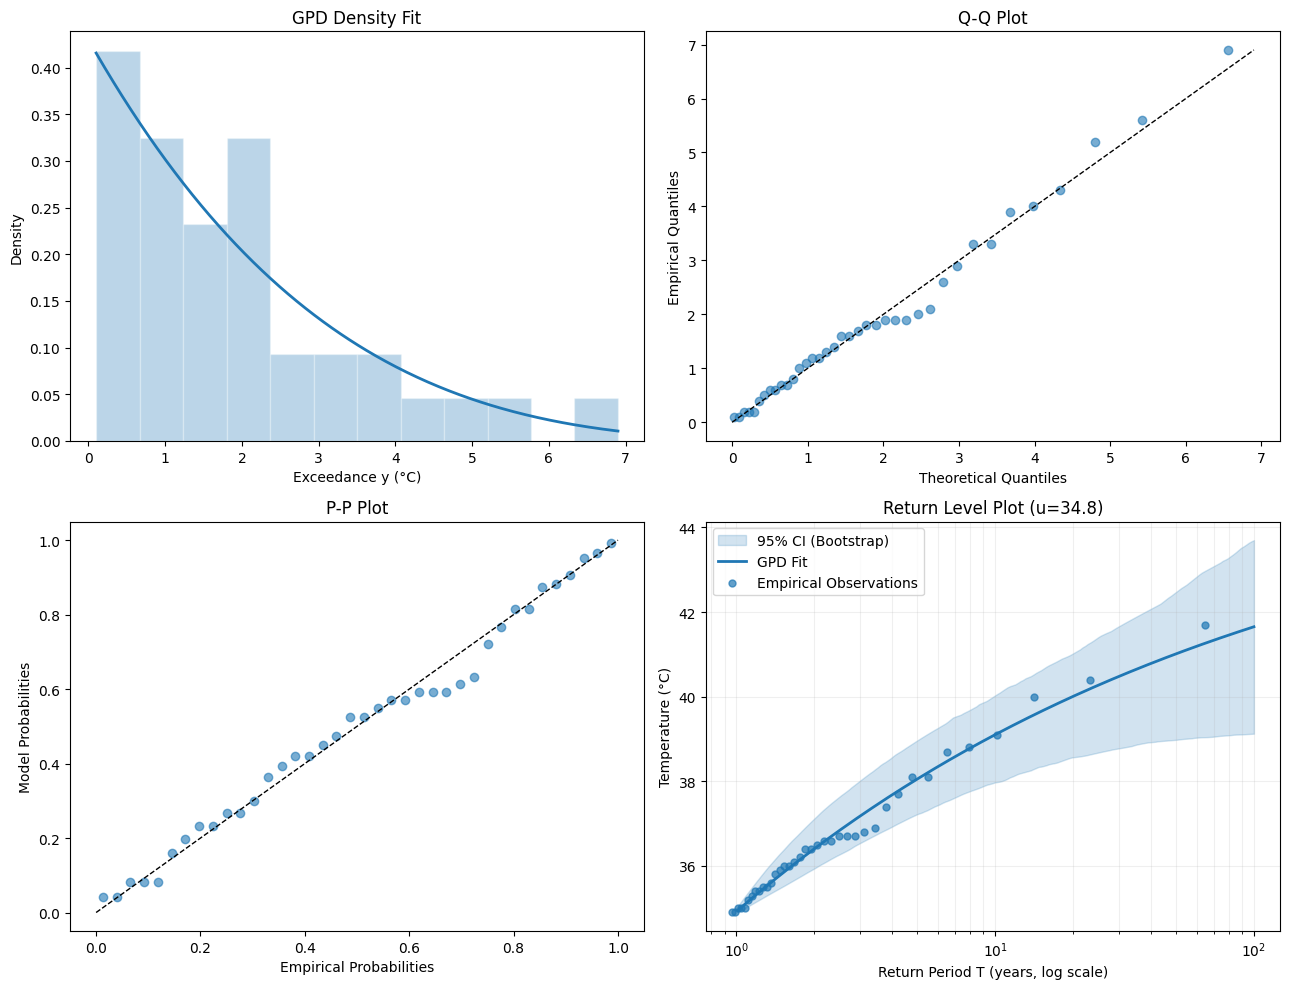

In [14]:
exc, exc_clusters = decluster_exceedances(df_summer, "tmax", u_star, run=RUN_DECLUSTER)
exc = np.asarray(exc, dtype=float)
exc = exc[~np.isnan(exc)]

xi, _, beta = genpareto.fit(exc, floc=0.0)
xi_exp, _, beta_exp = genpareto.fit(exc, floc=0.0, f0=0.0)

n_years = df_summer["year"].nunique()
rate_per_year = len(exc) / n_years

ll_gpd = np.sum(genpareto.logpdf(exc, xi, loc=0.0, scale=beta))
ll_exp = np.sum(genpareto.logpdf(exc, xi_exp, loc=0.0, scale=beta_exp))
lr_pot = 2.0 * (ll_gpd - ll_exp)
pval_lr_pot = 1.0 - chi2.cdf(lr_pot, df=1)

print(f"Fitted Params: xi = {xi:.4f}, beta = {beta:.4f}")
print(f"Annual exceedance rate (lambda): {rate_per_year:.3f}")
print(f"LR test GPD vs Exponential (xi=0): LR = {lr_pot:.3f}, p-value = {pval_lr_pot:.4f}")


emp_obs = np.sort(exc) + u_star 
n_exc = len(emp_obs)
ranks = np.arange(1, n_exc + 1)
p_emp = (ranks - 0.44) / (n_exc + 0.12)
t_emp = 1.0 / (rate_per_year * (1.0 - p_emp))
t_model = np.logspace(np.log10(1.01), np.log10(100), 200)

def pot_rl(u, xi, beta, lam, T):
    if abs(xi) < 1e-8:
        return u + beta * np.log(T * lam)
    else:
        return u + (beta / xi) * ((T * lam)**xi - 1)

rl_model = np.array([pot_rl(u_star, xi, beta, rate_per_year, T) for T in t_model])

B = 1000
rng = np.random.default_rng(42)
rl_boot = np.full((B, len(t_model)), np.nan)

print("Starting Bootstrap...")
for b in range(B):
    try:
        sim = genpareto.rvs(xi, loc=0.0, scale=beta, size=len(exc), random_state=rng)
        xi_b, _, beta_b = genpareto.fit(sim, floc=0.0)
        
        if beta_b > 0:
            rl_boot[b, :] = [pot_rl(u_star, xi_b, beta_b, rate_per_year, T) for T in t_model]
    except:
        continue


rl_lower = np.nanpercentile(rl_boot, 2.5, axis=0)
rl_upper = np.nanpercentile(rl_boot, 97.5, axis=0)
print(f"Bootstrap complete. Successful fits: {np.sum(~np.isnan(rl_boot[:,0]))}/{B}")


fig, axes = plt.subplots(2, 2, figsize=(13, 10))
main_color = "C0"

# GPD Density Fit 
xs = np.linspace(exc.min(), exc.max(), 300)
pdf = genpareto.pdf(xs, xi, loc=0.0, scale=beta)
axes[0, 0].hist(exc, bins=12, density=True, alpha=0.3, color=main_color, edgecolor="white")
axes[0, 0].plot(xs, pdf, color=main_color, lw=2)
axes[0, 0].set_title("GPD Density Fit")
axes[0, 0].set_xlabel("Exceedance y (°C)")
axes[0, 0].set_ylabel("Density")

# Q-Q Plot 
theo_q = genpareto.ppf((np.arange(1, n_exc+1)-0.5)/n_exc, xi, scale=beta)
axes[0, 1].scatter(theo_q, np.sort(exc), alpha=0.6, color=main_color)
axes[0, 1].plot([0, exc.max()], [0, exc.max()], "k--", lw=1)
axes[0, 1].set_title("Q-Q Plot")
axes[0, 1].set_xlabel("Theoretical Quantiles")
axes[0, 1].set_ylabel("Empirical Quantiles")

# P-P Plot 
axes[1, 0].scatter((np.arange(1, n_exc+1)-0.5)/n_exc, genpareto.cdf(np.sort(exc), xi, scale=beta), alpha=0.6, color=main_color)
axes[1, 0].plot([0, 1], [0, 1], "k--", lw=1)
axes[1, 0].set_title("P-P Plot")
axes[1, 0].set_xlabel("Empirical Probabilities")
axes[1, 0].set_ylabel("Model Probabilities")

# Return Level Plot with 95% CI
axes[1, 1].fill_between(t_model, rl_lower, rl_upper, color=main_color, alpha=0.2, label="95% CI (Bootstrap)")
axes[1, 1].plot(t_model, rl_model, color=main_color, lw=2, label="GPD Fit")
axes[1, 1].scatter(t_emp, emp_obs, s=25, alpha=0.7, label="Empirical Observations", zorder=3)
axes[1, 1].set_xscale("log")
axes[1, 1].set_title(f"Return Level Plot (u={u_star:.1f})")
axes[1, 1].set_xlabel("Return Period T (years, log scale)")
axes[1, 1].set_ylabel("Temperature (°C)")
axes[1, 1].grid(True, which="both", alpha=0.2)
axes[1, 1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, f"pot_diagnostics_u_{u_star:.1f}.png"), dpi=200)
plt.show()
plt.close()


## 10. Threshold sensitivity analysis for POT-GPD

Parameter / rate summary (declustered)
      u  n_exc  rate_per_year        xi      beta  upper_bound_est
0  33.5     63       1.750000 -0.249363  2.765495        44.590233
1  33.9     57       1.583333 -0.205512  2.461929        45.879506
2  34.4     46       1.277778 -0.204128  2.359805        45.960394
3  34.8     38       1.055556 -0.214561  2.325971        45.640608
4  35.5     28       0.777778 -0.213900  2.170749        45.648438
Return levels (declustered)
      u      RL_2y      RL_3y      RL_4y      RL_5y     RL_10y     RL_15y  \
0  33.5  36.475576  37.255919  37.763634  38.133117  39.158070  39.680452   
1  33.9  36.426733  37.182487  37.681768  38.049215  39.088835  39.631753   
2  34.4  36.415012  37.173243  37.674402  38.043361  39.087911  39.633822   
3  34.8  36.405835  37.175277  37.682003  38.054066  39.102462  39.647221   
4  35.5  36.415181  37.182228  37.687493  38.058546  39.104407  39.648049   

      RL_20y     RL_25y     RL_30y  
0  40.020329  40.267671  40.459

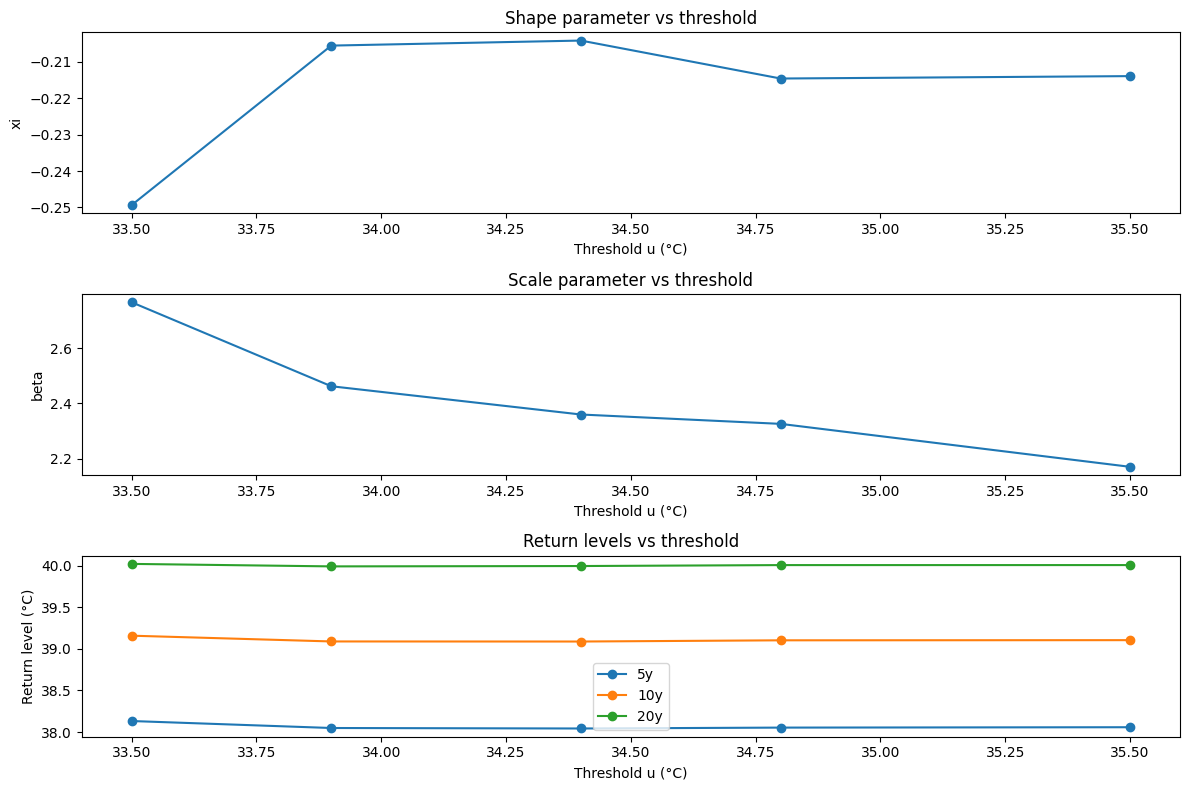

In [15]:
n_years = df_summer["year"].nunique()

# choose thresholds to compare
u_list = [33.5, 33.9, 34.4, 34.8, 35.5]

Ts = np.array([2, 3, 4, 5, 10, 15, 20, 25, 30], dtype=float)

rows = []
rl_rows = []

for u in u_list:
    exc_u, _ = decluster_exceedances(df_summer, "tmax", float(u), run=RUN_DECLUSTER)
    n_exc = len(exc_u)

    if n_exc < 20:
        print(f"Skip u={u:.3f} (declustered n_exc={n_exc} too small)")
        continue

    xi_u, _, beta_u = genpareto.fit(exc_u, floc=0.0)
    rate_per_year = n_exc / n_years
    rls = [pot_return_level(u, xi_u, beta_u, rate_per_year, T) for T in Ts]

    rows.append({
        "u": u,
        "n_exc": n_exc,
        "rate_per_year": rate_per_year,
        "xi": xi_u,
        "beta": beta_u,
        "upper_bound_est": (u - beta_u / xi_u) if xi_u < 0 else np.inf,
    })

    rl_rows.append({"u": u, **{f"RL_{int(T)}y": rl for T, rl in zip(Ts, rls)}})

summary = pd.DataFrame(rows).sort_values("u").reset_index(drop=True)
rl_table = pd.DataFrame(rl_rows).sort_values("u").reset_index(drop=True)

print("Parameter / rate summary (declustered)")
print(summary)

print("Return levels (declustered)")
print(rl_table)

fig, axes = plt.subplots(3, 1, figsize=(12, 8))

# xi vs u 
axes[0].plot(summary["u"], summary["xi"], marker="o")
axes[0].set_title("Shape parameter vs threshold")
axes[0].set_xlabel("Threshold u (°C)")
axes[0].set_ylabel("xi")


# beta vs u
axes[1].plot(summary["u"], summary["beta"], marker="o")
axes[1].set_title("Scale parameter vs threshold")
axes[1].set_xlabel("Threshold u (°C)")
axes[1].set_ylabel("beta")


# return levels vs u 
for horizon in [5, 10, 20]:
    col = f"RL_{horizon}y"
    if col in rl_table.columns:
        axes[2].plot(rl_table["u"], rl_table[col], marker="o", label=f"{horizon}y")

axes[2].set_title("Return levels vs threshold")
axes[2].set_xlabel("Threshold u (°C)")
axes[2].set_ylabel("Return level (°C)")
axes[2].legend()


plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "threshold_sensitivity.png"),
    dpi=200
)

plt.show()
plt.close()


## 11. Rebuild summer dry-spell events from the full series

In [37]:
DRY_THR = 0.1       
MIN_SPELL = 3   
SUMMER_MONTHS = [6, 7, 8]
SUMMER_START_MONTH = 6
SUMMER_START_DAY = 1
SUMMER_END_MONTH = 8
SUMMER_END_DAY = 31

def build_summer_dry_spell_events(
    df_in: pd.DataFrame,
    prcp_col: str = "prcp",
    tmax_col: str = "tmax",
    dry_thr: float = DRY_THR,
    min_spell: int = MIN_SPELL,
    keep_rule: str = "start_in_jja",
):
    req = ["time", "year", "month", prcp_col, tmax_col]
    tmp = df_in[req].copy().sort_values("time").reset_index(drop=True)

    events = []
    run_idx = []

    def flush_run(idxs):
        if len(idxs) == 0:
            return
        sub = tmp.loc[idxs].copy()
        start_date = sub["time"].iloc[0]
        end_date = sub["time"].iloc[-1]
        year0 = int(start_date.year)

        jja_start = pd.Timestamp(year=year0, month=SUMMER_START_MONTH, day=SUMMER_START_DAY)
        jja_end = pd.Timestamp(year=year0, month=SUMMER_END_MONTH, day=SUMMER_END_DAY)

        if keep_rule == "start_in_jja":
            keep = start_date.month in SUMMER_MONTHS
        elif keep_rule == "overlap_jja":
            keep = not (end_date < jja_start or start_date > jja_end)
        else:
            raise ValueError("keep_rule must be 'start_in_jja' or 'overlap_jja'")

        if (len(sub) >= min_spell) and keep:
            t_season = (start_date - jja_start).days + 1  # June 1 -> 1
            overlap_start = max(start_date, jja_start)
            overlap_end = min(end_date, jja_end)

            events.append({
                "year": year0,
                "start_date": start_date,
                "end_date": end_date,
                "duration": int(len(sub)),
                "mean_tmax": float(sub[tmax_col].mean()) if sub[tmax_col].notna().any() else np.nan,
                "max_tmax": float(sub[tmax_col].max()) if sub[tmax_col].notna().any() else np.nan,
                "total_prcp": float(sub[prcp_col].sum()) if sub[prcp_col].notna().any() else np.nan,
                "t_season": int(t_season),
                "start_month": int(start_date.month),
                "start_day": int(start_date.day),
                "overlap_jja_days": int((overlap_end - overlap_start).days + 1) if overlap_start <= overlap_end else 0,
            })

    for i in range(len(tmp)):
        p = tmp.loc[i, prcp_col]
        is_dry = pd.notna(p) and (float(p) <= dry_thr)

        if i == 0:
            if is_dry:
                run_idx = [i]
            continue

        gap = (tmp.loc[i, "time"] - tmp.loc[i - 1, "time"]).days
        prev_p = tmp.loc[i - 1, prcp_col]
        prev_is_dry = pd.notna(prev_p) and (float(prev_p) <= dry_thr)

        if is_dry and prev_is_dry and gap == 1:
            run_idx.append(i)
        else:
            flush_run(run_idx)
            run_idx = [i] if is_dry else []

    flush_run(run_idx)

    events = pd.DataFrame(events).sort_values(["year", "start_date"]).reset_index(drop=True)
    events = events[(events["t_season"] >= 1) & (events["t_season"] <= 92)].copy()
    return events

events = build_summer_dry_spell_events(
    df,
    prcp_col="prcp",
    tmax_col="tmax",
    dry_thr=DRY_THR,
    min_spell=MIN_SPELL,
    keep_rule="start_in_jja",   
)

print("Number of summer dry-spell events:", len(events))
display(events.head())


Number of summer dry-spell events: 249


,year,start_date,end_date,duration,mean_tmax,max_tmax,total_prcp,t_season,start_month,start_day,overlap_jja_days
0,1990,1990-06-10,1990-06-16,7,17.542857,21.1,0.0,10,6,10,7
1,1990,1990-07-09,1990-07-27,19,27.778947,34.3,0.0,39,7,9,19
2,1990,1990-07-29,1990-08-13,16,30.350000,37.4,0.0,59,7,29,16
3,1990,1990-08-19,1990-08-23,5,25.720000,28.3,0.0,80,8,19,5
4,1990,1990-08-26,1990-08-28,3,28.066667,30.3,0.0,87,8,26,3


## 12. Build the year-bin panel for the dry-spell NHPP


In [38]:
SUMMER_LENGTH = 92
BIN_WIDTH = 10  
def make_piecewise_edges(T=SUMMER_LENGTH, width=BIN_WIDTH):
    edges = list(range(1, T + 1, width))
    if edges[-1] != T + 1:
        edges.append(T + 1)
    return np.array(edges, dtype=int)

edges = make_piecewise_edges(T=SUMMER_LENGTH, width=BIN_WIDTH)
n_bins = len(edges) - 1

all_years = np.arange(df["year"].min(), df["year"].max() + 1)

events_pp = events.copy()
events_pp["bin_id"] = pd.cut(
    events_pp["t_season"],
    bins=edges,
    right=False,
    labels=False,
    include_lowest=True,
)

panel_rows = []
for y in all_years:
    for b in range(n_bins):
        left = int(edges[b])
        right = int(edges[b + 1])
        exposure = right - left  
        cnt = int(((events_pp["year"] == y) & (events_pp["bin_id"] == b)).sum())
        panel_rows.append({
            "year": int(y),
            "bin_id": int(b),
            "bin_left": left,
            "bin_right": right,
            "bin_mid": 0.5 * (left + right - 1),
            "exposure": float(exposure),
            "count": cnt,
        })

panel = pd.DataFrame(panel_rows)

print("Piecewise NHPP panel shape:", panel.shape)
display(panel.head(12))


Piecewise NHPP panel shape: (360, 7)


,year,bin_id,bin_left,bin_right,bin_mid,exposure,count
0,1990,0,1,11,5.5,10.0,1
1,1990,1,11,21,15.5,10.0,0
2,1990,2,21,31,25.5,10.0,0
3,1990,3,31,41,35.5,10.0,1
4,1990,4,41,51,45.5,10.0,0
5,1990,5,51,61,55.5,10.0,1
6,1990,6,61,71,65.5,10.0,0
7,1990,7,71,81,75.5,10.0,1
8,1990,8,81,91,85.5,10.0,1
9,1990,9,91,93,91.5,2.0,0


## 13. Fit homogeneous Poisson and piecewise NHPP


In [39]:
# homogeneous Poisson intensity
m0 = smf.glm(
    formula="count ~ 1",
    data=panel,
    family=sm.families.Poisson(),
    offset=np.log(panel["exposure"])
).fit()

# piecewise-constant NHPP
m1 = smf.glm(
    formula="count ~ C(bin_id) - 1",
    data=panel,
    family=sm.families.Poisson(),
    offset=np.log(panel["exposure"])
).fit()

print("Homogeneous Poisson (baseline)")
print(m0.summary())

print("\nPiecewise-constant NHPP")
print(m1.summary())

lambda_hom = float(np.exp(m0.params.iloc[0]))

lambda_bins = np.exp(m1.params)
lambda_bins = pd.DataFrame({
    "bin_id": range(n_bins),
    "bin_left": edges[:-1],
    "bin_right": edges[1:],
    "lambda_hat": lambda_bins.values,
})
lambda_bins["bin_mid"] = 0.5 * (lambda_bins["bin_left"] + lambda_bins["bin_right"] - 1)

model_compare = pd.DataFrame({
    "model": ["homogeneous Poisson", "piecewise NHPP"],
    "AIC": [m0.aic, m1.aic],
    "logLik": [m0.llf, m1.llf],
    "df_model": [m0.df_model, m1.df_model],
})

print("\nEstimated homogeneous intensity per day:", lambda_hom)
display(lambda_bins)
print("\nAIC comparison:")
display(model_compare)


Homogeneous Poisson (baseline)
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  count   No. Observations:                  360
Model:                            GLM   Df Residuals:                      359
Model Family:                 Poisson   Df Model:                            0
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -352.34
Date:                Wed, 11 Mar 2026   Deviance:                       255.20
Time:                        22:43:52   Pearson chi2:                     202.
No. Iterations:                     5   Pseudo R-squ. (CS):         -2.220e-16
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.5879

,bin_id,bin_left,bin_right,lambda_hat,bin_mid
0,0,1,11,0.063889,5.5
1,1,11,21,0.077778,15.5
2,2,21,31,0.075000,25.5
3,3,31,41,0.080556,35.5
4,4,41,51,0.069444,45.5
5,5,51,61,0.075000,55.5
6,6,61,71,0.072222,65.5
7,7,71,81,0.075000,75.5
8,8,81,91,0.088889,85.5
9,9,91,93,0.069444,91.5



AIC comparison:


,model,AIC,logLik,df_model
0,homogeneous Poisson,706.678906,-352.339453,0
1,piecewise NHPP,722.781529,-351.390764,9


## 14. Occurrence-intensity diagnostics


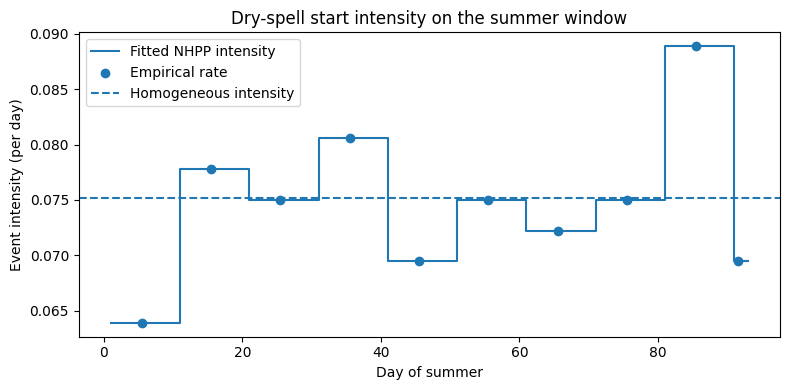

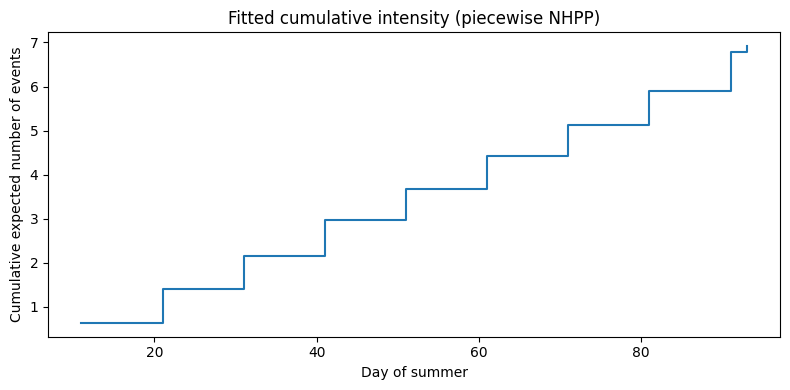

In [48]:
lambda_bins = lambda_bins.sort_values("bin_id").reset_index(drop=True)

emp = panel.groupby("bin_id", as_index=False).agg(
    total_count=("count", "sum"),
    total_exposure=("exposure", "sum"),
    bin_left=("bin_left", "first"),
    bin_right=("bin_right", "first"),
    bin_mid=("bin_mid", "first"),
)
emp = emp.sort_values("bin_id").reset_index(drop=True)
emp["emp_rate"] = emp["total_count"] / emp["total_exposure"]

plt.figure(figsize=(8, 4))
plt.step(
    np.r_[lambda_bins["bin_left"].values, lambda_bins["bin_right"].values[-1]],
    np.r_[lambda_bins["lambda_hat"].values, lambda_bins["lambda_hat"].values[-1]],
    where="post",
    label="Fitted NHPP intensity",
)
plt.scatter(emp["bin_mid"], emp["emp_rate"], label="Empirical rate")
plt.axhline(lambda_hom, linestyle="--", label="Homogeneous intensity")
plt.xlabel("Day of summer")
plt.ylabel("Event intensity (per day)")
plt.title("Dry-spell start intensity on the summer window")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "poisson_intensity_fit.png"), dpi=200)
plt.show()
plt.close()


# cumulative mean count per year implied by the fitted NHPP
lambda_bins["bin_length"] = lambda_bins["bin_right"] - lambda_bins["bin_left"]
lambda_bins["cum_mean_count"] = (lambda_bins["lambda_hat"] * lambda_bins["bin_length"]).cumsum()

plt.figure(figsize=(8, 4))
plt.step(
    lambda_bins["bin_right"].values,
    lambda_bins["cum_mean_count"].values,
    where="post",
)
plt.xlabel("Day of summer")
plt.ylabel("Cumulative expected number of events")
plt.title("Fitted cumulative intensity (piecewise NHPP)")
plt.tight_layout()
plt.show()

## 15. Time-rescaling diagnostics


Number of uncensored transformed waits: 249
Mean uncensored transformed wait (ideal approx. 1): 0.9056671128960911
Number of right-censored season tails: 36
Number of seasons with no event: 0
Mean censored tail in transformed time: 0.6524691358174985
Uniform KS test: statistic = 0.207, p-value = 0.0000


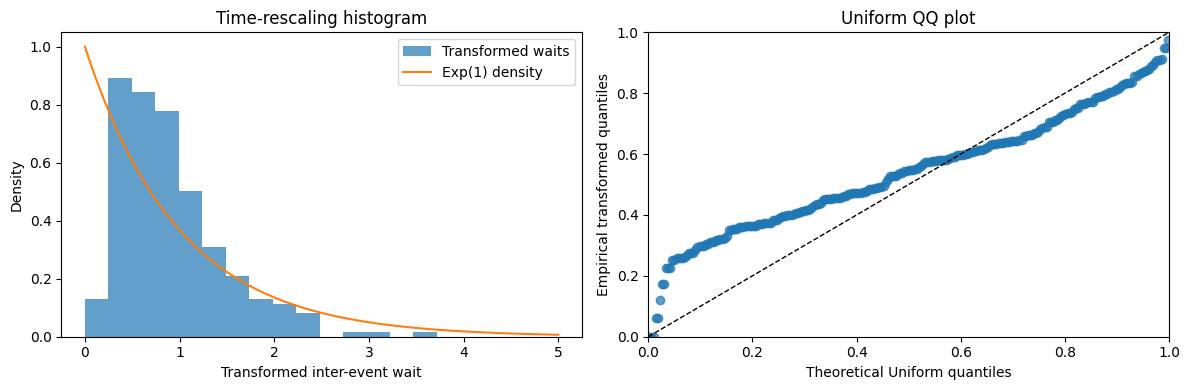

In [44]:
def cumulative_intensity_piecewise(t, lambda_df):
    """Compute estimated cumulative intensity for the fitted piecewise NHPP."""
    if pd.isna(t):
        return np.nan
    t = float(t)
    if t <= 1:
        return 0.0

    total = 0.0
    for _, row in lambda_df.iterrows():
        left = float(row["bin_left"])
        right = float(row["bin_right"])
        lam = float(row["lambda_hat"])
        if t >= right:
            total += lam * (right - left)
        elif t > left:
            total += lam * (t - left)
            break
        else:
            break
    return total

season_end = float(edges[-1])
season_total_intensity = cumulative_intensity_piecewise(season_end, lambda_bins)

z_waits = []
z_tail_censored = []
events_sorted = events.sort_values(["year", "t_season"]).copy()

for y in all_years:
    sub = events_sorted.loc[events_sorted["year"] == y]
    ts = np.sort(sub["t_season"].values.astype(float))
    if len(ts) == 0:
        z_tail_censored.append(season_total_intensity)
        continue
    Lambda_ts = np.array([cumulative_intensity_piecewise(t, lambda_bins) for t in ts])
    prev = 0.0
    for cur in Lambda_ts:
        z_waits.append(cur - prev)
        prev = cur
    z_tail_censored.append(season_total_intensity - Lambda_ts[-1])

z_waits = np.asarray(z_waits, dtype=float)
z_tail_censored = np.asarray(z_tail_censored, dtype=float)
u_waits = 1.0 - np.exp(-z_waits)
ks_uniform = stats.kstest(u_waits, "uniform")

print("Number of uncensored transformed waits:", len(z_waits))
print("Mean uncensored transformed wait (ideal approx. 1):", np.nanmean(z_waits))
print("Number of right-censored season tails:", len(z_tail_censored))
print("Number of seasons with no event:", int(np.sum(z_tail_censored == season_total_intensity)))
print("Mean censored tail in transformed time:", np.nanmean(z_tail_censored))
print(f"Uniform KS test: statistic = {ks_uniform.statistic:.3f}, p-value = {ks_uniform.pvalue:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xx = np.linspace(0, max(5, np.nanmax(z_waits)), 200)
axes[0].hist(z_waits, bins=15, density=True, alpha=0.7, label="Transformed waits")
axes[0].plot(xx, stats.expon.pdf(xx), label="Exp(1) density")
axes[0].set_xlabel("Transformed inter-event wait")
axes[0].set_ylabel("Density")
axes[0].set_title("Time-rescaling histogram")
axes[0].legend()

u_sorted = np.sort(u_waits)
u_theory = (np.arange(1, len(u_sorted) + 1) - 0.5) / len(u_sorted)
axes[1].scatter(u_theory, u_sorted, alpha=0.7)
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Theoretical Uniform quantiles")
axes[1].set_ylabel("Empirical transformed quantiles")
axes[1].set_title("Uniform QQ plot")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, f"transformed_gaps_histogram.png"), dpi=200)
plt.show()
plt.close()


## 16. Conditional mark model for dry-spell duration


                 Generalized Linear Model Regression Results                  
Dep. Variable:               duration   No. Observations:                  249
Model:                            GLM   Df Residuals:                      246
Model Family:                 Poisson   Df Model:                            2
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -748.56
Date:                Wed, 11 Mar 2026   Deviance:                       590.78
Time:                        22:43:53   Pearson chi2:                     701.
No. Iterations:                     4   Pseudo R-squ. (CS):            0.03776
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.9754      0.036     54.408      0.0

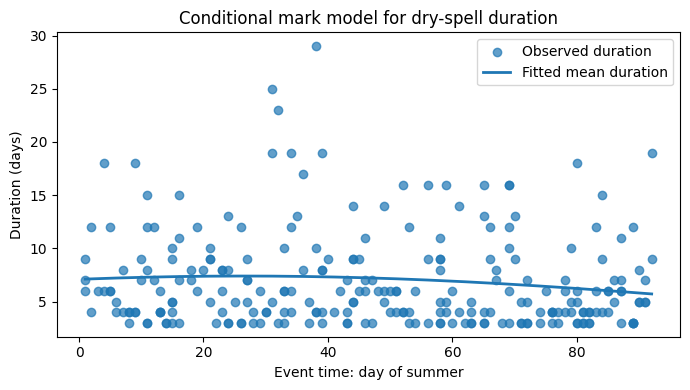

In [42]:
marks = events.copy()

marks["t_c"] = marks["t_season"] - marks["t_season"].mean()
marks["t_c2"] = marks["t_c"] ** 2

# Poisson GLM for duration as a first simple conditional mark model
mark_duration_glm = smf.glm(
    formula="duration ~ t_c + t_c2",
    data=marks,
    family=sm.families.Poisson()
).fit()

print(mark_duration_glm.summary())

# fitted conditional mean duration
marks["duration_hat"] = mark_duration_glm.predict(marks)

plt.figure(figsize=(7, 4))
plt.scatter(marks["t_season"], marks["duration"], alpha=0.7, label="Observed duration")
ord_idx = np.argsort(marks["t_season"].values)
plt.plot(
    marks["t_season"].values[ord_idx],
    marks["duration_hat"].values[ord_idx],
    linewidth=2,
    label="Fitted mean duration",
)
plt.xlabel("Event time: day of summer")
plt.ylabel("Duration (days)")
plt.title("Conditional mark model for dry-spell duration")
plt.legend()
plt.tight_layout()
plt.show()


## 17. Auxiliary mark model for mean temperature


                            OLS Regression Results                            
Dep. Variable:              mean_tmax   R-squared:                       0.145
Model:                            OLS   Adj. R-squared:                  0.138
Method:                 Least Squares   F-statistic:                     20.92
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           4.08e-09
Time:                        22:43:53   Log-Likelihood:                -605.36
No. Observations:                 249   AIC:                             1217.
Df Residuals:                     246   BIC:                             1227.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     27.1264      0.268    101.272      0.0

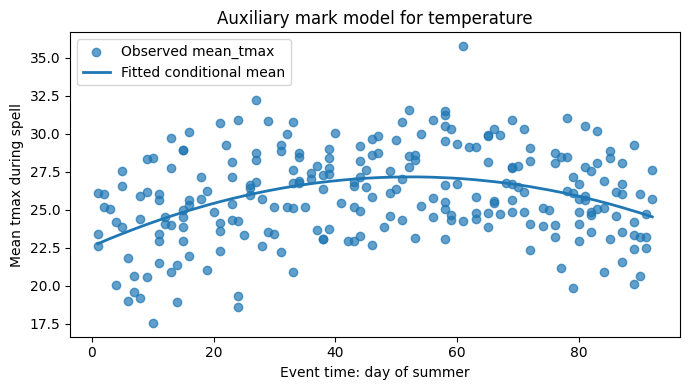

In [43]:
# Optional auxiliary mark model
marks_temp = marks.dropna(subset=["mean_tmax"]).copy()
marks_temp["t_c"] = marks_temp["t_season"] - marks_temp["t_season"].mean()
marks_temp["t_c2"] = marks_temp["t_c"] ** 2

# Gaussian model for the temperature mark
mark_temp_ols = smf.ols(
    formula="mean_tmax ~ t_c + t_c2",
    data=marks_temp
).fit()

print(mark_temp_ols.summary())

marks_temp["mean_tmax_hat"] = mark_temp_ols.predict(marks_temp)

plt.figure(figsize=(7, 4))
plt.scatter(marks_temp["t_season"], marks_temp["mean_tmax"], alpha=0.7, label="Observed mean_tmax")
ord_idx = np.argsort(marks_temp["t_season"].values)
plt.plot(
    marks_temp["t_season"].values[ord_idx],
    marks_temp["mean_tmax_hat"].values[ord_idx],
    linewidth=2,
    label="Fitted conditional mean",
)
plt.xlabel("Event time: day of summer")
plt.ylabel("Mean tmax during spell")
plt.title("Auxiliary mark model for temperature")
plt.legend()
plt.tight_layout()
plt.show()
